In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import networkx as nx

## Preparations

### Generate data splits for Toy-Problem

1000 dots are chosen uniformly on $[-2,2]\times[-2,2]$, then assigned to one of 3 folds either randomly or by angular sector (not radially -- the split is based on the angle $\theta$ around the origin, not the distance from it), which serves as a simplified DataSAIL output. In that case, the dimensionality of the data is r = 1 and the number of classes is c = 1.

In [3]:
def assign_triangle_labels(X):

    Y2 = np.zeros(len(X), dtype=int)

    theta = np.arctan2(X[:, 1], X[:, 0])  # in [-pi, pi]
    theta = theta % (2 * np.pi)            # map to [0, 2pi]

    Y2[(theta >= 0) & (theta < 2*np.pi/3)] = 1
    Y2[(theta >= 2*np.pi/3) & (theta < 4*np.pi/3)] = 2
    Y2[(theta >= 4*np.pi/3) & (theta < 2*np.pi)] = 3

    return Y2

def data(n=1000):
    X = np.random.uniform(-2, 2, (n, 2))
    Y1 = np.random.choice([1, 2, 3], size=len(X))
    Y2 = assign_triangle_labels(X)
    return X, Y1, Y2

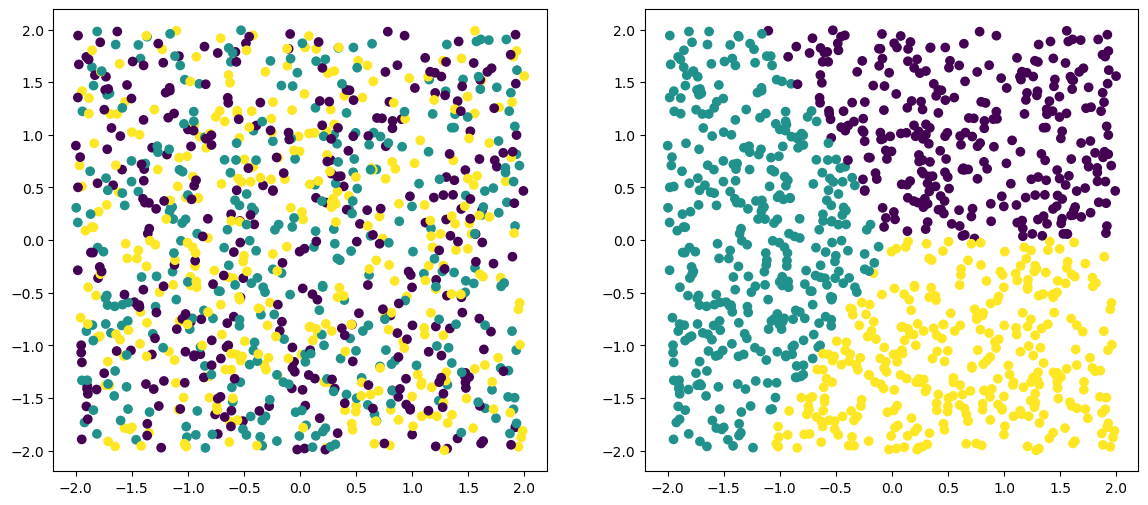

In [4]:
X, Y1, Y2 = data(n=1000)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(X[:, 0], X[:, 1], c=Y1)
axes[1].scatter(X[:, 0], X[:, 1], c=Y2)
plt.show()

### Splits as dictionaries

From here on, every split (`D`, `E`, ...) and the data itself (`points`) are
plain `{point_id: value}` dictionaries. This mirrors the structure DataSAIL
itself returns from `datasail(...)`.

Previously, a problem occurred during graph cycle decomposition: not all edges were assigned to a cycle. The reason for that was not a poorly designed algorithm, but a difference in the number of points per fold. For each fold i, `out-degree(i) - in-degree(i) = |D_i| - |E_i|`, and this difference need not be 0. When it isn't, the graph is unbalanced, and by Euler's theorem a directed multigraph has an Eulerian circuit (and can therefore be fully decomposed into cycles) only if every node has equal in- and out-degree.

How can we fix it?
1. E is constructed as a random split that EXACTLY preserves D's split fractions. This, however, makes E slightly less random than a fully independent draw.
2. Since DataSAIL already keeps fold cardinalities close to equal, only a small number of points would likely be left unassigned to any cycle. We could instead accept this residual, sort the leftover points by their individual leakage contribution, and append them to the ranked cycle list directly.

In [12]:
def to_dict(values, cast=None):
    """
    Convert a positional array/list into an id-keyed dict {0: v0, 1: v1, ...}.
    """
    if cast is None:
        return {i: v for i, v in enumerate(values)}
    return {i: cast(v) for i, v in enumerate(values)}


points = to_dict(X)          # point index -> (x, y) coordinates
D = to_dict(Y2, cast=int)    # point index  -> fold (structured as "triangle")

# Create new E as described in (1) 

rng = np.random.default_rng()
E = to_dict(rng.permutation(np.array(list(D.values()))), cast=int) 

# Sanity check

d_counts = pd.Series(D.values()).value_counts().sort_index()
e_counts = pd.Series(E.values()).value_counts().sort_index()
print("D fold sizes:\n", d_counts)
print("E fold sizes:\n", e_counts)


D fold sizes:
 1    302
2    366
3    332
Name: count, dtype: int64
E fold sizes:
 1    302
2    366
3    332
Name: count, dtype: int64


## The Algorithm

### Multigraph construction

In [13]:
def build_graph(D, E):
    """Edge i -> j for each point x where D[x] = i and E[x] = j, i != j."""
    G = nx.MultiDiGraph()
    G.add_nodes_from(set(D.values()) | set(E.values())) # D.values() and E.values() are the same, but this avoids some instant errors if they are not
    for point_id, i in D.items():
        j = E[point_id]
        if i != j:
            G.add_edge(i, j, point_id=point_id)
    return G

### Cycle Decomposition
Here, an iterative Hierholzer-style traversal is used: O(V + E) total, since each edge is popped from its adjacency list exactly once and every "have we seen this node before" check is an O(1) dict lookup.

In [14]:
def decompose_into_cycles(G):
    """
    Decompose the edges of a balanced directed multigraph into edge-disjoint
    simple cycles.
    """

    # adjacency: node -> [(neighbor, point_id), ...], used as a stack
    adj = {n: [] for n in G.nodes()} # adj = {1: [], 2: [], 3: []}
    for u, v, d in G.edges(data=True):
        adj[u].append((v, d['point_id'])) # we can read that as "you can go from node u to node v, and doing so corresponds to moving point_id"

    cycles = []
    for start in list(G.nodes()): # let's start from all possible nodes
        while adj[start]:
            stack_nodes  = [start] # path of nodes visited so far in this walk 
            stack_points = [] #what point_ids are we using for this path
            pos = {start: 0}   # node -> index in stack_nodes (O(1) repeat check)

            while True:
                node = stack_nodes[-1]
                if not adj[node]:
                    break # in case of balance happens only when node == start
                nxt, pt = adj[node].pop() #take last direction from current node and delete, meaning mark as visited
                stack_points.append(pt)

                if nxt in pos:
                    # Hallelujah! The cycle is closed. We record stack_points, and delete the path
                    idx = pos[nxt]
                    cycles.append(stack_points[idx:])
                    del stack_points[idx:]
                    for removed in stack_nodes[idx + 1:]:
                        del pos[removed]
                    del stack_nodes[idx + 1:]
                else: #continue the path
                    stack_nodes.append(nxt)
                    pos[nxt] = len(stack_nodes) - 1

    return cycles

In [17]:
G = build_graph(D, E)
cycles = decompose_into_cycles(G)

print(f"Total cycles: {len(cycles)}")

# Sanity check: total points in cycles must equal total edges in G (no loss)
print(f"Total points in cycles: {sum(len(c) for c in cycles)}")
print(f"Total edges in G: {G.number_of_edges()}")

Total cycles: 318
Total points in cycles: 646
Total edges in G: 646


### Leakage function
Copied from the original DataSAIL implementation and adapted for this toy case. Similarity is defined as $\frac{1}{1+ ||x-x'||}$, so it equals 1 when the two points coincide, and asymptotically approaches (but never reaches) 0 as they grow further apart.

In [22]:
def leakage(split, points):
    ids = list(points.keys())
    coords = np.array([points[i] for i in ids])
    metric = 1/(1 + np.linalg.norm(coords[:, None, :] - coords[None, :, :], axis=-1)) # (n, n) similarity

    in_split_mask = np.zeros((len(ids), len(ids)))
    for s in set(split.values()):
        v = np.array([split[i] == s for i in ids], dtype=int).reshape(-1, 1)
        in_split_mask += v @ v.T                      # 1 iff same split

    weight_array = np.ones(len(ids)).reshape(-1, 1)   # kappa(x) = 1
    weight_matrix = weight_array @ weight_array.T

    total = np.sum(metric * weight_matrix)
    leakage = np.sum((1 - in_split_mask) * weight_matrix * metric)
    return leakage/total

In [23]:
L_D = leakage(D, points)
L_E = leakage(E, points)
print(f"Leakage D (triangle split): {L_D:.4f}")
print(f"Leakage E (random split):   {L_E:.4f}")

Leakage D (triangle split): 0.5622
Leakage E (random split):   0.6633


### Ranking cycles
First, define the function that will actually apply each cycle to a specific split. It is then straightforward to sort all cycles by their effect on leakage.

### Ranking cycles efficiently

Ranking every cycle by calling `leakage()` on it directly means rebuilding the whole O(n^2) similarity sum once per cycle -- for a few hundred cycles, that adds up fast. A cycle only swaps the fold of its own (usually 2-6) points, so only the pairs touching those points can actually change; everything else in the leakage sum stays exactly as it was. `rank_cycles` builds the similarity matrix once, then looks at just those few rows per cycle (O(|cycle|*n) each), so ranking every cycle costs about as much as a single `leakage()` call in total, not one per cycle. Since `total` (the denominator in `leakage`) is the same positive constant for every split, it cannot change the ordering, so we skip dividing by it here -- this only affects the ranking order slightly for pairs within the same cycle (double-counted), which does not matter since it is a heuristic ordering, not the leakage value itself.

In [ ]:
def apply_cycle(split, cycle_points):
    """ Rotate fold assignments of split along one cycle of point_ids."""
    new_split = split.copy()
    n = len(cycle_points)
    for i, pt in enumerate(cycle_points):
        next_pt = cycle_points[(i + 1) % n]
        new_split[pt] = split[next_pt]
    return new_split


def rank_cycles(cycles, D, points):
    """Sort cycles by how much applying each one (in isolation) to D would
    change the leakage -- see the explanation above."""
    ids = list(points.keys())
    id_to_pos = {pid: i for i, pid in enumerate(ids)}
    coords = np.array([points[i] for i in ids])
    folds = np.array([D[i] for i in ids])
    metric = 1 / (1 + np.linalg.norm(coords[:, None, :] - coords[None, :, :], axis=-1))

    def cycle_delta(cycle_points):
        pos = np.array([id_to_pos[pt] for pt in cycle_points])
        old, new = folds[pos], np.roll(folds[pos], -1)
        row = metric[pos]                                     # (|cycle|, n), not (n, n)
        return ((new[:, None] != folds) * row).sum() - ((old[:, None] != folds) * row).sum()

    return sorted(((cycle, cycle_delta(cycle)) for cycle in cycles), key=lambda cr: cr[1])


# Rank every cycle by how much it changes the leakage if applied to D.
cycle_results_sorted = rank_cycles(cycles, D, points)

In [ ]:
def apply_k_cycles(split, points, cycle_results_sorted, k, verbose=True):
    """Apply the first k cycles (by leakage-delta order) and, optionally, report L."""
    new_split = dict(split)
    for cycle_points, _ in cycle_results_sorted[:k]:
        new_split = apply_cycle(new_split, cycle_points)
    if verbose:
        print(f"After {k:>4} cycles: L = {leakage(new_split, points):.4f}")
    return new_split


def plot_split(points, split):
    ids = list(points.keys())
    coords = np.array([points[i] for i in ids])
    folds  = np.array([split[i]  for i in ids])
    plt.figure(figsize=(6, 5))
    plt.scatter(coords[:, 0], coords[:, 1], c=folds, cmap='viridis')
    plt.show()

Show the split gradually morphing from D (triangle split) into E (random split) as more leakage-ranked cycles get applied.

After    0 cycles: L = 0.5622


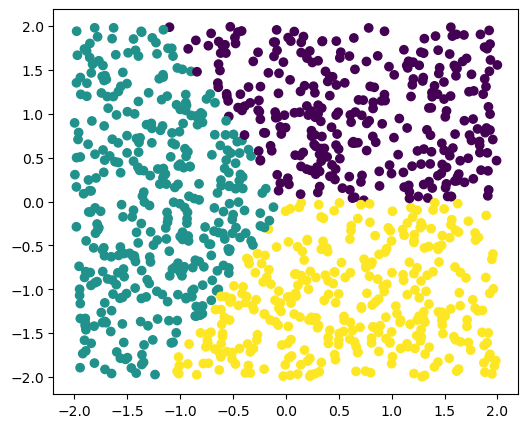

After   79 cycles: L = 0.5875


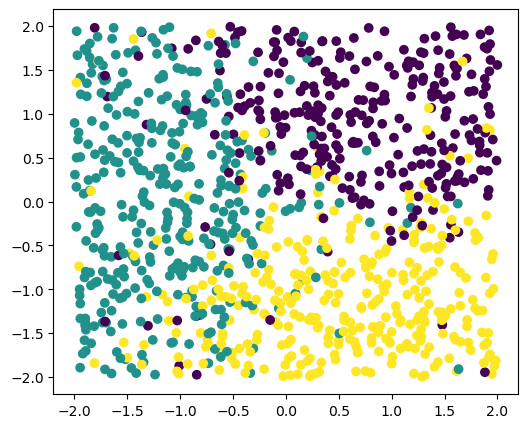

After  159 cycles: L = 0.6208


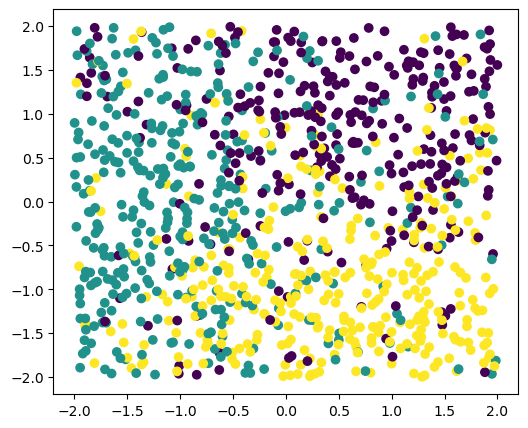

After  238 cycles: L = 0.6491


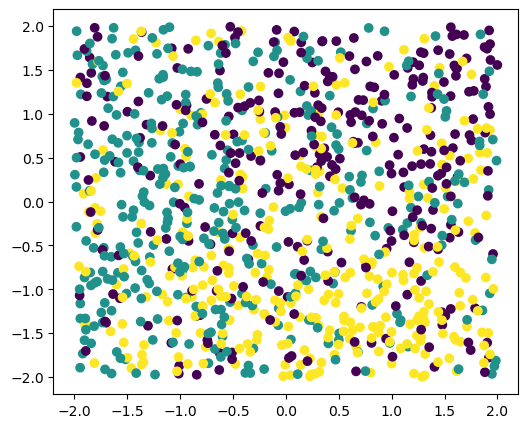

After  318 cycles: L = 0.6633


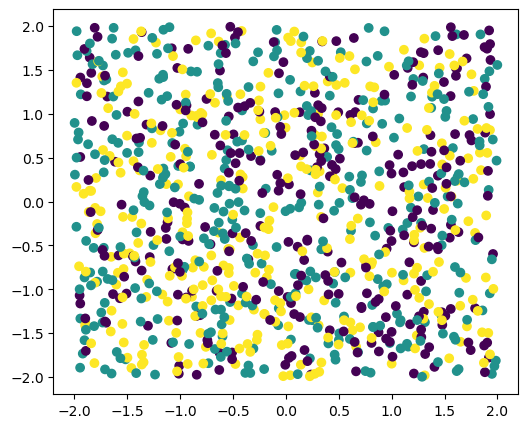

In [31]:
k_values = sorted(set([0, len(cycles)//4, len(cycles)//2, 3*len(cycles)//4, len(cycles)]))

for k in k_values:
    D_new = apply_k_cycles(D, points, cycle_results_sorted, k)
    plot_split(points, D_new)

And it does so monotonically!

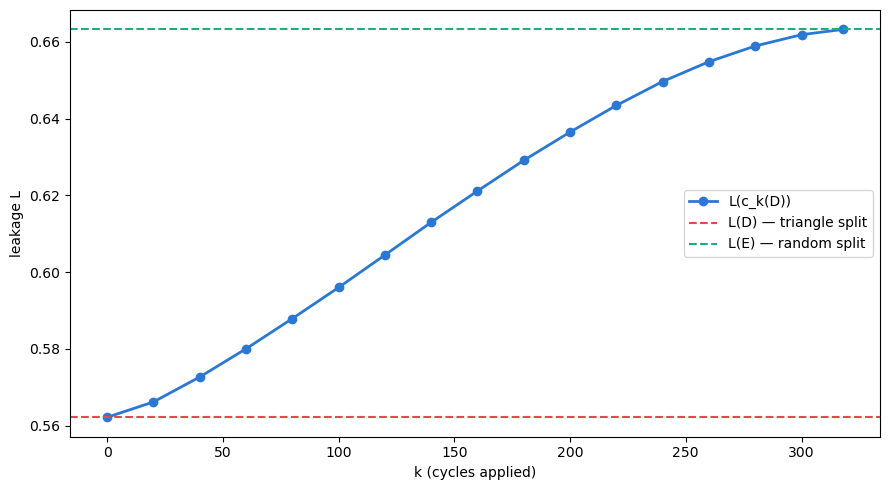

In [32]:
k_steps = list(range(0, len(cycles), 20)) + [len(cycles)]
leakages = []

D_current = dict(D)
prev_k = 0

for k in k_steps:
    for cycle_points, _ in cycle_results_sorted[prev_k:k]:
        D_current = apply_cycle(D_current, cycle_points)
    leakages.append(leakage(D_current, points))
    prev_k = k

plt.figure(figsize=(9, 5))
plt.plot(k_steps, leakages, 'o-', color='#2a78d6', lw=2, label='L(c_k(D))')
plt.axhline(L_D, color='#e34948', lw=1.5, ls='--', label='L(D) — triangle split')
plt.axhline(L_E, color='#1baf7a', lw=1.5, ls='--', label='L(E) — random split')
plt.xlabel('k (cycles applied)')
plt.ylabel('leakage L')
plt.legend()
plt.tight_layout()
plt.show()

### Final Result Function

Now, using everything defined above, create the final function. It should return the split, k cycles from D, whose leakage best approximates `percentage` percent of the way from L(D) to L(E). For example:
1. percentage =   0 -> D itself (0 cycles applied)
2. percentage = 100 -> E itself (all cycles applied)
3. percentage =  50 -> whichever k lands leakage closest to the midpoint

In [ ]:
def continuous_split(D, E, points, percentage):
    """
    Returns:
        split:    dict, point_id -> fold
        k:        number of cycles applied to reach it
        achieved: the leakage-interpolation percentage actually achieved,
                  as a fraction in [0, 1]
    """
    if not (0 <= percentage <= 100):
        raise ValueError("percentage must be between 0 and 100")

    G = build_graph(D, E)
    cycles = decompose_into_cycles(G)
    cycle_results_sorted = rank_cycles(cycles, D, points)

    L_D = leakage(D, points)
    L_E = leakage(E, points)
    target = L_D + percentage / 100 * (L_E - L_D)
    N = len(cycle_results_sorted)

    lo, hi = 0, N
    best_k, best_split, best_L = 0, D, L_D
    while lo <= hi:
        mid = (lo + hi) // 2
        split_mid = apply_k_cycles(D, points, cycle_results_sorted, mid, verbose=False)
        L_mid = leakage(split_mid, points)
        if abs(L_mid - target) < abs(best_L - target):
            best_k, best_split, best_L = mid, split_mid, L_mid
        if L_mid < target:
            lo = mid + 1
        else:
            hi = mid - 1

    achieved = 0.0 if L_E == L_D else (best_L - L_D) / (L_E - L_D)
    print(f"percentage={percentage:>5.1f}%  ->  k={best_k} cycles, "
          f"achieved={achieved * 100:.2f}%, L={best_L:.4f}")
    return best_split, best_k, achieved


# Demo: sweep the interpolation from D to E
for pct in [0, 25, 50, 75, 100]:
    split_pct, k_pct, achieved_pct = continuous_split(D, E, points, pct)
    plot_split(points, split_pct)